# Activity: Should We Trust the Alarm? — FreshKart Cold-Chain Case

**Unit 4 · AI-Assisted Visualization · AI-Assisted Pattern and Anomaly Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

FreshKart's dark stores keep frozen food in **8 freezers** (one per store in Bengaluru, Pune and Hyderabad). Each freezer reports its temperature every hour. Last month FreshKart bought **ColdSense**, an AI service that scores every reading for "anomaly" and raises an alert when the score is **≥ 0.5**.

Cold-chain lead **Ravi** has six weeks of readings, the ColdSense scores, and the **maintenance log** (what technicians actually found). His technicians are tired of being sent out at night. He asks:

> *"Is ColdSense's alert feed trustworthy? Which alerts should my team chase, and what is it missing?"*

**You are the analyst.** Use the data and the visualizations to verify, correct or reject what the vendor claims.

**Ground rules (from the lecture):** an AI score is a *derived attribute*: look at it, don't only threshold it · flags are **candidates, not conclusions** · report precision and recall, not accuracy · scale emphasis to confidence.

**How to work:** This activity has been completed. Run the notebook top to bottom to reproduce all calculations and visualizations. Keep `freshkart_coldchain.csv` in the same folder as this notebook.

### The data: `freshkart_coldchain.csv` (synthetic)

| Column | Meaning |
|---|---|
| `timestamp` | hour of the reading (1 Aug – 11 Sep 2026) |
| `city`, `store_id`, `freezer_id` | where the freezer is |
| `temp_c` | freezer temperature (°C); normal is about −18 °C |
| `door_opens` | number of door openings in that hour (busy by day, quiet at night) |
| `compressor_kw` | compressor power draw (kW) |
| `ai_score`, `ai_flag` | ColdSense anomaly score (0–1) and alert (1 if score ≥ 0.5) |
| `confirmed_fault`, `fault_type` | from the maintenance log: 1 if technicians confirmed a real fault in that hour, and what it was |

**Domain note from the maintenance team:** every freezer runs an automatic **defrost cycle from 02:00 to 04:00** each night. The heater warms the coil, so the temperature rises for those two hours. That is normal.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])  # Place the supplied CSV beside this notebook.
df["hour"] = df["timestamp"].dt.hour
df.head()

,timestamp,city,store_id,freezer_id,temp_c,door_opens,compressor_kw,ai_score,ai_flag,confirmed_fault,fault_type,hour
0,2026-08-01,Bengaluru,B1,FZ-B1,-18.1,0,1.29,0.000,0,0,NaN,0
1,2026-08-01,Bengaluru,B2,FZ-B2,-18.7,0,1.16,0.000,0,0,NaN,0
2,2026-08-01,Bengaluru,B3,FZ-B3,-17.7,0,1.21,0.000,0,0,NaN,0
3,2026-08-01,Hyderabad,H1,FZ-H1,-17.8,0,1.30,0.037,0,0,NaN,0
4,2026-08-01,Hyderabad,H2,FZ-H2,-18.2,0,1.32,0.035,0,0,NaN,0


## ColdSense's monthly report (to be validated)

| # | Vendor statement |
|---|---|
| 1 | "ColdSense is **97.9% accurate**, so its alerts can be trusted." |
| 2 | "**Most faults happen around 2 am.** We recommend a night technician." |
| 3 | "**All 10 compressor trips** in the period were caught." |
| 4 | "Freezer **FZ-H2 ran without a single fault** in August." |
| 5 | "A reading of **−14 °C is abnormal** for any freezer, at any time." |
| 6 | "An alert with a score of **0.92 means a 92% chance** of a real fault." |
| 7 | "The **default threshold of 0.5** is the best setting for FreshKart." |
| 8 | "A new FZ-B1 reading of **−15.9 °C at 14:00** is **15 standard errors** above normal: a definite fault." |

---
## Part 1 · Data abstraction: items, attributes and derived attributes

Munzner: before choosing a view, ask what the **items** and **attributes** are. The AI does not change the items; it **derives** new attributes.

In [3]:
derived_cols = ["ai_score", "ai_flag"]  # ColdSense-derived attributes
n_alerts = int((df["ai_flag"] == 1).sum())
fault_rate_pct = round(100 * df["confirmed_fault"].mean(), 2)

if ready(derived_cols, n_alerts, fault_rate_pct):
    print(f"derived: {derived_cols} | alerts: {n_alerts} | faults: {df.confirmed_fault.sum()} of {len(df)} rows ({fault_rate_pct}%)")
    display(df[df.confirmed_fault == 1].groupby("fault_type").size().rename("fault hours"))

derived: ['ai_score', 'ai_flag'] | alerts: 159 | faults: 46 of 8064 rows (0.57%)


,fault hours
fault_type,
compressor trip,10
defrost heater stuck,11
sensor frozen,25


**✏️ Your answer (Part 1):** `ai_score` is quantitative and `ai_flag` is binary. Which **visual channel** suits each, and what information does the flag throw away that the score keeps?

**Answer:** Use a **quantitative magnitude channel** (position on an axis, or sequential colour intensity) for `ai_score`, because its numerical ordering and distance matter. Use a **binary identity channel** (such as two hues or different marker shapes) for `ai_flag`. The flag discards score magnitude and distance from the threshold: scores of 0.50 and 0.99 appear identical, while scores of 0.49 and 0.50 appear completely different.

---
## Part 2 · Distributions: bin width and the score distribution

### 2a · Temperature histogram

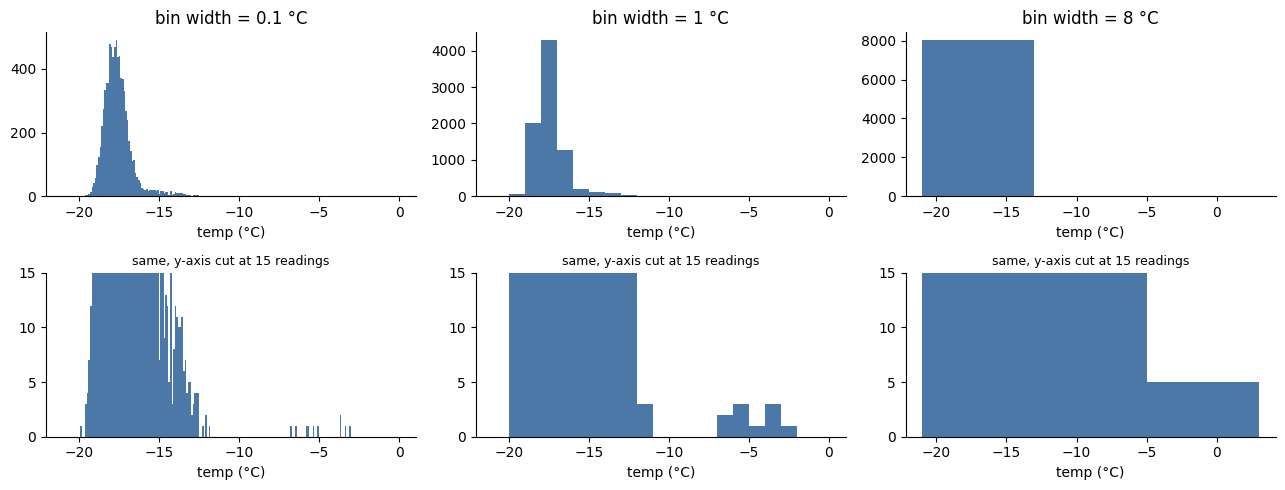

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for col, w in enumerate([0.1, 1, 8]):
    for row, top in enumerate([None, 15]):
        ax = axes[row, col]
        ax.hist(df["temp_c"], bins=np.arange(-21, 0 + w, w), color=BLUE)
        if top: ax.set_ylim(0, top); ax.set_title(f"same, y-axis cut at {top} readings", fontsize=9)
        else: ax.set_title(f"bin width = {w} °C")
        ax.set_xlabel("temp (°C)")
plt.tight_layout(); plt.show()

warm_tail_visible_bins = [0.1, 1]  # These resolve all ten very warm readings; 8 °C bins merge some with the main distribution.
n_warm_readings = int((df["temp_c"] > -8).sum())

### 2b · Look at the AI scores before trusting the cut-off
Wilke: compare groups with overlapping densities, not stacked histograms.

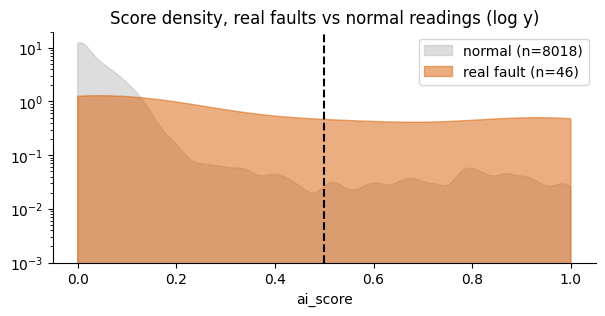

In [5]:
xs = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 3))
for lab, col in [(0, GREY), (1, ACCENT)]:
    s = df.loc[df.confirmed_fault == lab, "ai_score"]
    ax.fill_between(xs, stats.gaussian_kde(s)(xs), color=col, alpha=.5, label=f"{'real fault' if lab else 'normal'} (n={len(s)})")
ax.axvline(0.5, color="k", ls="--"); ax.set_yscale("log"); ax.set_ylim(1e-3, 20)
ax.set_xlabel("ai_score"); ax.legend(); ax.set_title("Score density, real faults vs normal readings (log y)")
plt.show()

scores_separate_faults = False  # The normal and fault score distributions overlap.

**✏️ Your answer (Part 2):** Why is a histogram "a parameterised algorithm", and what would you tell a colleague who says *"the 8 °C histogram shows no anomalies"*?

**Answer:** A histogram is a **parameterised algorithm** because its appearance depends on the chosen bin width, bin boundaries and axis limits, which determine what structure is visible. The 8 °C bins hide or merge much of the warm tail with other readings; this does **not** prove anomalies are absent. With 0.1 °C or 1 °C bins and a suitable y-axis, we can see **10 readings warmer than −8 °C**. Inspect finer bins and the underlying records before drawing a conclusion.

---
## Part 3 · Outlier rules on a short window (vendor statement 3)

Ten consecutive readings from **FZ-P1**, 12 Aug 06:00–15:00. One of them is a compressor trip.

In [6]:
window = df[(df.freezer_id == "FZ-P1") & (df.timestamp >= "2026-08-12 06:00") & (df.timestamp < "2026-08-12 16:00")]
v = window["temp_c"].values
print(window[["timestamp", "temp_c", "fault_type"]].to_string(index=False))

z_max = float(np.max(np.abs((v - v.mean()) / np.std(v, ddof=1))))
q1, q3 = np.percentile(v, [25, 75])
upper_fence = float(q3 + 1.5 * (q3 - q1))

if ready(z_max, upper_fence):
    print(f"largest |z| = {z_max:.2f} -> flagged by |z| > 3? {z_max > 3}")
    print(f"upper IQR fence = {upper_fence:.2f} °C -> trip flagged by IQR rule? {v.max() > upper_fence}")
    print(f"largest |z| possible with n = {len(v)}: {(len(v) - 1) / np.sqrt(len(v)):.2f}")

          timestamp  temp_c      fault_type
2026-08-12 06:00:00   -17.5             NaN
2026-08-12 07:00:00   -18.2             NaN
2026-08-12 08:00:00   -17.4             NaN
2026-08-12 09:00:00   -17.7             NaN
2026-08-12 10:00:00   -16.6             NaN
2026-08-12 11:00:00    -3.6 compressor trip
2026-08-12 12:00:00   -17.0             NaN
2026-08-12 13:00:00   -16.8             NaN
2026-08-12 14:00:00   -17.7             NaN
2026-08-12 15:00:00   -17.7             NaN
largest |z| = 2.83 -> flagged by |z| > 3? False
upper IQR fence = -15.58 °C -> trip flagged by IQR rule? True
largest |z| possible with n = 10: 2.85


**✏️ Your answer (Part 3):** Explain in two sentences why the z-score rule missed the trip here (use the word *masking*) and why the IQR rule did not.

**Answer:** The extreme compressor-trip reading (−3.6 °C) inflates the sample mean and standard deviation, producing **masking**: the largest absolute z-score is only about **2.83**, below the threshold of 3. The IQR rule uses the central 50% of the readings, so the extreme value has little effect on its upper fence (about **−15.58 °C**) and is correctly flagged.

---
## Part 4 · How good is ColdSense? (vendor statement 1)

In [7]:
flag = df.ai_flag == 1
real = df.confirmed_fault == 1

TP = int((flag & real).sum())
FP = int((flag & ~real).sum())
FN = int((~flag & real).sum())
TN = int((~flag & ~real).sum())

if ready(TP, FP, FN, TN):
    display(pd.DataFrame([[TP, FN], [FP, TN]], index=["real fault", "normal"], columns=["alert", "no alert"]))

,alert,no alert
real fault,16,30
normal,143,7875


In [8]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)
accuracy = (TP + TN) / (TP + FP + FN + TN)
flag_nothing_accuracy = (TN + FP) / len(df)  # All normal readings are predicted normal.

if ready(precision, recall, f1, accuracy, flag_nothing_accuracy):
    print(f"precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f} | accuracy = {accuracy:.1%} | never-alert accuracy = {flag_nothing_accuracy:.1%}")

precision = 0.10 | recall = 0.35 | F1 = 0.16 | accuracy = 97.9% | never-alert accuracy = 99.4%


**✏️ Your answer (Part 4):** Rewrite vendor statement 1 so it is honest. Use precision and recall, and say in plain words what they mean for Ravi's technicians (how many call-outs are wasted, how many faults are missed).

**Answer:** The vendor's **97.9% accuracy** is mathematically correct but misleading because confirmed faults are rare (**46 of 8,064 readings, or 0.57%**). At threshold 0.5, **precision is 10.1%**: of **159 call-outs, 143 are false alarms**. **Recall is 34.8%**: ColdSense finds only **16 of 46 fault-hours** and misses **30**. A system that never alerts would achieve **99.4% accuracy**, demonstrating why accuracy alone does not establish trustworthiness.

---
## Part 5 · Thresholds and costs (vendor statement 7)

A missed fault can spoil a freezer of stock (cost ≈ **40** units); a false call-out costs **1** unit of technician time.

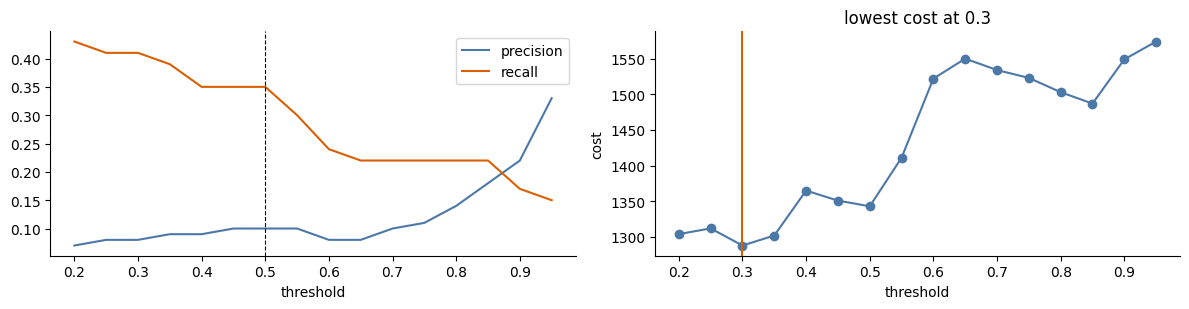

,threshold,TP,FP,FN,precision,recall,cost
0,0.20,20,264,26,0.07,0.43,1304
1,0.25,19,232,27,0.08,0.41,1312
2,0.30,19,208,27,0.08,0.41,1288
3,0.35,18,182,28,0.09,0.39,1302
4,0.40,16,165,30,0.09,0.35,1365
5,0.45,16,151,30,0.10,0.35,1351
6,0.50,16,143,30,0.10,0.35,1343
7,0.55,14,131,32,0.10,0.30,1411
8,0.60,11,122,35,0.08,0.24,1522
9,0.65,10,110,36,0.08,0.22,1550


In [9]:
grid = np.round(np.arange(0.20, 0.96, 0.05), 2)
sweep = pd.DataFrame({"threshold": grid})
sweep["TP"] = [((df.ai_score >= g) & real).sum() for g in grid]
sweep["FP"] = [((df.ai_score >= g) & ~real).sum() for g in grid]
sweep["FN"] = real.sum() - sweep["TP"]
sweep["precision"] = (sweep.TP / (sweep.TP + sweep.FP)).round(2)
sweep["recall"] = (sweep.TP / real.sum()).round(2)

sweep["cost"] = 40 * sweep["FN"] + sweep["FP"]
best_threshold = float(sweep.loc[sweep["cost"].idxmin(), "threshold"])

if ready(best_threshold) and sweep["cost"].notna().all():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    ax[0].plot(sweep.threshold, sweep.precision, color=BLUE, label="precision"); ax[0].plot(sweep.threshold, sweep.recall, color=ACCENT, label="recall")
    ax[0].axvline(0.5, color="k", ls="--", lw=.8); ax[0].legend(); ax[0].set_xlabel("threshold")
    ax[1].plot(sweep.threshold, sweep.cost.astype(float), color=BLUE, marker="o"); ax[1].axvline(best_threshold, color=ACCENT)
    ax[1].set_xlabel("threshold"); ax[1].set_ylabel("cost"); ax[1].set_title(f"lowest cost at {best_threshold}")
    plt.tight_layout(); plt.show()
    display(sweep)

**✏️ Your answer (Part 5):** Even at the best threshold, recall stays low. Why can no threshold fix this detector? (Hint: look at *which* faults are never scored high.)

**Answer:** The lowest-cost threshold in the tested grid is **0.30** (cost **1,288**, compared with **1,343** at 0.50), but it still catches only **19 of 46 fault-hours** (41.3% recall). A threshold only changes which *existing scores* count as alerts; it cannot make a pointwise detector recognise the **25 sensor-frozen hours** that receive low scores because each individual temperature looks normal. Detecting these collective anomalies requires **time-series or run-length features**, not just threshold tuning.

---
## Part 6 · Where do the errors come from?

### 6a · When do the false alarms happen? (vendor statement 2)

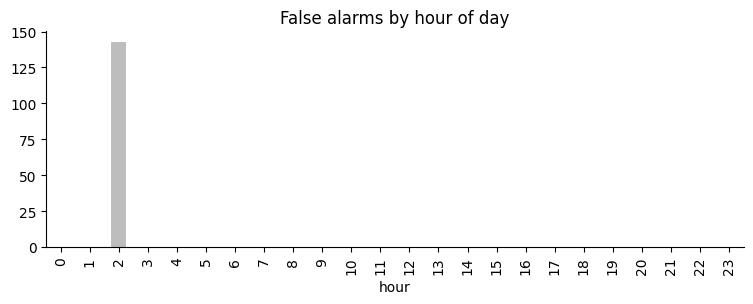

100% of false alarms happen at 2:00


In [10]:
fp_rows = df[flag & ~real]
fp_rows.groupby("hour").size().reindex(range(24), fill_value=0).plot.bar(color=GREY, title="False alarms by hour of day", figsize=(9, 2.8))
plt.show()

fp_counts = fp_rows.groupby("hour").size()
fp_peak_hour = int(fp_counts.idxmax())
fp_share_at_peak = float(fp_counts.max() / len(fp_rows))

if ready(fp_peak_hour, fp_share_at_peak):
    print(f"{fp_share_at_peak:.0%} of false alarms happen at {fp_peak_hour}:00")

### 6b · Which faults does ColdSense miss?

In [11]:
caught = df[real].groupby("fault_type")["ai_flag"].agg(caught="sum", fault_hours="size")
caught["recall"] = (caught.caught / caught.fault_hours).round(2)
display(caught)

never_caught_type = str(caught.index[caught["caught"] == 0][0])
anomaly_kind = "collective"  # The readings are suspicious as a long, unnaturally flat sequence.

,caught,fault_hours,recall
fault_type,,,
compressor trip,10,10,1.00
defrost heater stuck,6,11,0.55
sensor frozen,0,25,0.00


### 6c · Contextual anomalies: compare each reading with its own hour

A **context-aware** baseline compares each reading with the same freezer at the same hour of day (median and MAD over the six weeks).

In [12]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]
df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(lambda s: 1.4826 * stats.median_abs_deviation(s))

df["z_context"] = (df["temp_c"] - df["hour_median"]) / df["hour_mad"].replace(0, np.nan)

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4
    found = df[real & ctx_flag & ~flag]
    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")
    display(found[["timestamp", "freezer_id", "temp_c", "hour_median", "z_context", "ai_score", "fault_type"]])
    print(f"False alarms at 02:00 under the context baseline: {(ctx_flag & ~real & (df.hour == 2)).sum()} (ColdSense: {(flag & ~real & (df.hour == 2)).sum()})")

Real faults the context baseline catches but ColdSense missed: 3


,timestamp,freezer_id,temp_c,hour_median,z_context,ai_score,fault_type
1279,2026-08-07 15:00:00,FZ-P2,-14.6,-17.50,4.890058,0.369,defrost heater stuck
4731,2026-08-25 15:00:00,FZ-H1,-14.8,-17.50,6.070417,0.388,defrost heater stuck
6273,2026-09-02 16:00:00,FZ-B2,-15.2,-17.35,4.143300,0.189,defrost heater stuck


False alarms at 02:00 under the context baseline: 0 (ColdSense: 143)


### 6d · Collective anomalies: a run of readings that is abnormal together

                           min                 max  count
freezer_id                                               
FZ-H2      2026-08-20 14:00:00 2026-08-20 22:00:00      9
FZ-P1      2026-09-06 12:00:00 2026-09-06 17:00:00      6


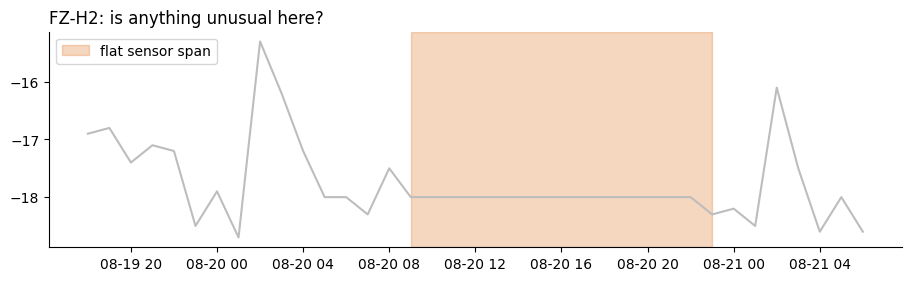

In [13]:
df = df.sort_values(["freezer_id", "timestamp"])
df["roll_sd_6h"] = df.groupby("freezer_id")["temp_c"].transform(lambda s: s.rolling(6).std())

flat = df[df["roll_sd_6h"] < 0.01].copy()  # Nearly constant temperatures across six hours.

if ready(flat):
    print(flat.groupby("freezer_id")["timestamp"].agg(["min", "max", "count"]))
    h2 = df[(df.freezer_id == "FZ-H2") & (df.timestamp.between("2026-08-19 18:00", "2026-08-21 06:00"))]
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(h2.timestamp, h2.temp_c, color=GREY)
    h2_flat = flat[flat["freezer_id"] == "FZ-H2"]
    if not h2_flat.empty:
        # A 6-hour rolling window first becomes flat at the sixth constant reading.
        span_start = h2_flat["timestamp"].min() - pd.Timedelta(hours=5)
        span_end = h2_flat["timestamp"].max() + pd.Timedelta(hours=1)
        ax.axvspan(span_start, span_end, color=ACCENT, alpha=.25, label="flat sensor span")
        ax.legend(loc="upper left")

    ax.set_title("FZ-H2: is anything unusual here?", loc="left"); plt.show()
df = df.sort_values(["timestamp", "store_id"])

**✏️ Your answer (Part 6):**
(a) Rewrite vendor statement 2. What really happens at 2 am, and what would happen if FreshKart hired a night technician based on the vendor's report?
(b) Is vendor statement 5 true? Use the words *contextual anomaly* and say what a chart must show for a viewer to judge such an alert.
(c) What is wrong with vendor statement 4, and why can a detector that scores readings one at a time never catch this kind of fault?

**Answer:** **(a)** Vendor statement 2 is false: **all 143 false alarms occur at 02:00**, but **no confirmed fault-hour occurs at 02:00**. The alarms are caused by the routine defrost cycle; hiring a night technician on this evidence would waste resources rather than address actual fault risk.

**(b)** Vendor statement 5 is false: **−14 °C may be expected during defrost but unusual at other hours**. This is a **contextual anomaly** question; the chart must show each reading alongside the *same freezer's normal range at that hour*, with defrost periods and relevant history visible. A same-hour median/MAD baseline recovers **3 missed heater-fault hours** and generates **0 false alarms at 02:00** under the tested rule.

**(c)** Vendor statement 4 is false: maintenance records show **14 sensor-frozen hours in FZ-H2 on 20 August**. Each reading is a plausible **−18.0 °C**, but the uninterrupted flat run is a **collective anomaly**; a detector scoring readings independently cannot identify the abnormal absence of variation without temporal features.

---
## Part 7 · Highlighting, saliency and frequency framing (vendor statement 6)

### 7a · Emphasis scaled to confidence
The vendor's dashboard paints every alert bright red. Implement the lecture's checklist: **≥ 0.90 strong**, **0.70–0.90 moderate**, **0.50–0.70 subtle outline**, **below 0.50 no emphasis** (the data stays visible).

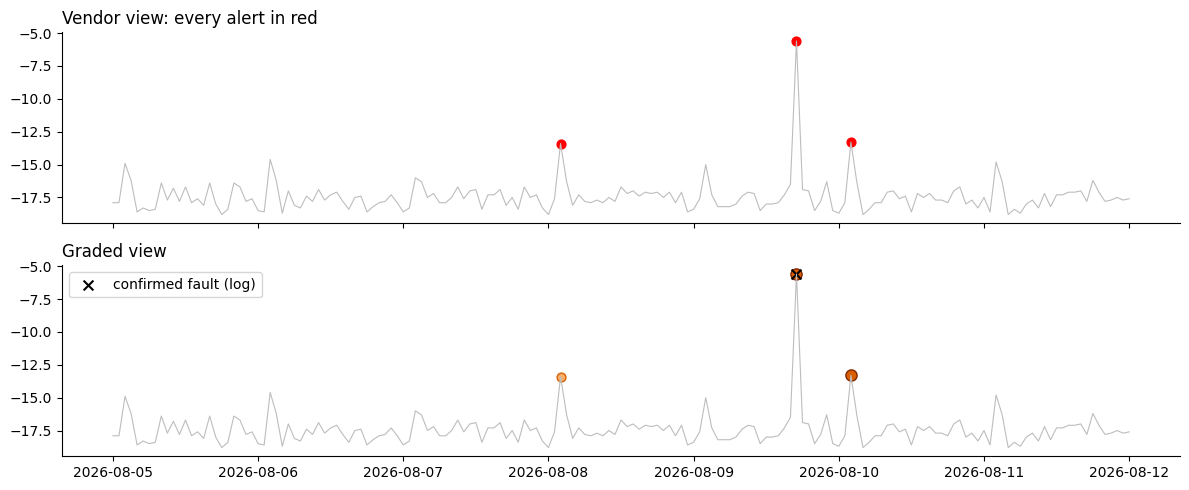

In [14]:
def emphasis(score):
    """Return (colour, marker size, edge colour) for one reading."""
    if score >= 0.90:
        return (ACCENT, 65, "#7f2704")      # Strong: saturated orange, large mark
    if score >= 0.70:
        return ("#fdae6b", 40, ACCENT)    # Moderate: softer orange
    if score >= 0.50:
        return ("none", 32, BLUE)          # Subtle: outline only
    return (GREY, 12, "none")             # No emphasis; the reading remains visible

week = df[(df.freezer_id == "FZ-B2") & (df.timestamp.between("2026-08-05", "2026-08-12"))]
if ready(emphasis(0.95)):
    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    ax[0].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    a = week[week.ai_flag == 1]; ax[0].scatter(a.timestamp, a.temp_c, color="red", s=40); ax[0].set_title("Vendor view: every alert in red", loc="left")
    ax[1].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    for _, r in week[week.ai_score >= 0.5].iterrows():
        col, size, edge = emphasis(r.ai_score)
        ax[1].scatter(r.timestamp, r.temp_c, color=col, s=size, edgecolors=edge)
    f_ = week[week.confirmed_fault == 1]; ax[1].scatter(f_.timestamp, f_.temp_c, marker="x", color="k", s=50, label="confirmed fault (log)")
    ax[1].legend(loc="upper left"); ax[1].set_title("Graded view", loc="left"); plt.tight_layout(); plt.show()

### 7b · "A score of 0.92 means 92%"? Count it.
Wilke: people read probabilities better as **frequencies**. Of all alerts in a score band, how many were real?

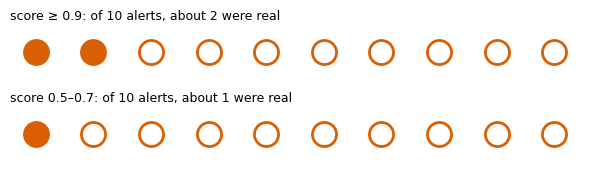

In [15]:
band_hi = df[df.ai_score >= 0.9]
band_lo = df[(df.ai_score >= 0.5) & (df.ai_score < 0.7)]

real_per_10_hi = round(10 * band_hi["confirmed_fault"].mean())
real_per_10_lo = round(10 * band_lo["confirmed_fault"].mean())

if ready(real_per_10_hi, real_per_10_lo):
    fig, ax = plt.subplots(2, 1, figsize=(6, 1.8))
    for a_, k, lab in zip(ax, [real_per_10_hi, real_per_10_lo], ["score ≥ 0.9", "score 0.5–0.7"]):
        for i in range(10): a_.scatter(i, 0, s=300, color=ACCENT if i < k else "white", edgecolors=ACCENT, linewidths=2)
        a_.axis("off"); a_.set_title(f"{lab}: of 10 alerts, about {k} were real", loc="left", fontsize=9)
    plt.tight_layout(); plt.show()

**✏️ Your answer (Part 7):** (a) Why does a red dot at every alert make Ravi's team **more** likely to miss the frozen H2 sensor? Use the words *salience* and *inattentional blindness*. (b) Rewrite vendor statement 6 using frequency framing.

**Answer:** **(a)** Making every alert equally bright red gives normal 02:00 defrost events disproportionate **salience**, exhausting attention and creating **inattentional blindness** to a genuinely unusual *pattern*—the long flat H2 sensor trace, which ColdSense never flags. Show all temperatures in context and use graded emphasis plus a separate flatline warning instead.

**(b)** The score is an anomaly ranking, **not a calibrated probability**. Among the **37 readings with score ≥ 0.90**, only **8 are confirmed faults**—roughly **2 out of 10**. For scores **0.50–0.70**, **6 of 55** are faults—roughly **1 out of 10**. So a score of 0.92 must **not** be described as a 92% chance of a fault.

---
## Part 8 · Standard deviation vs standard error (vendor statement 8)

The vendor judged a new FZ-B1 reading of **−15.9 °C at 14:00** against the 14:00 baseline.

In [16]:
base = df[(df.freezer_id == "FZ-B1") & (df.hour == 14) & (df.confirmed_fault == 0)]["temp_c"]
mu, sd, n = base.mean(), base.std(), len(base)
new_reading = -15.9

se = sd / np.sqrt(n)
z_sd = (new_reading - mu) / sd
z_se = (new_reading - mu) / se

if ready(se, z_sd, z_se):
    print(f"baseline: mean {mu:.2f} °C, SD {sd:.2f}, n = {n}, SE = {se:.3f}")
    print(f"z using SD = {z_sd:.1f} | z using SE = {z_se:.1f}")

correct_z = "SD"  # Use reading-to-reading variability for a single new observation.

baseline: mean -17.31 °C, SD 0.61, n = 42, SE = 0.094
z using SD = 2.3 | z using SE = 15.0


**✏️ Your answer (Part 8):** In one sentence each, say what the SD and the SE describe, and rewrite vendor statement 8.

**Answer:** **SD** describes the spread of individual temperature readings around their baseline mean. **SE** describes the uncertainty in the estimated *mean* and shrinks as the number of baseline readings grows. **Corrected statement 8:** FZ-B1's −15.9 °C reading at 14:00 is about **2.3 SD above** its usual 14:00 mean (−17.31 °C); it is worth reviewing in context, but is **not a definite fault**. The vendor's approximately **15 SE** figure answers the wrong question because we are judging a *single new reading*, not estimating the mean.

---
## Part 9 · Triage the vendor report

For each statement decide: **Accept** (correct as stated), **Correct** (useful, but the wording or number must change) or **Reject** (not supported). Then measure the report.

In [17]:
decisions = {
    1: "Correct",  # 97.9% accuracy is true, but does not make the alerts trustworthy.
    2: "Reject",   # The 02:00 spike is false alarms from normal defrost cycles.
    3: "Accept",   # All 10 compressor-trip hours are indeed flagged.
    4: "Reject",   # FZ-H2 has a 14-hour sensor-frozen fault.
    5: "Reject",   # Whether -14 °C is unusual depends on freezer and hour.
    6: "Reject",   # AI anomaly scores are not calibrated probabilities.
    7: "Correct",  # 0.30 beats 0.50 on the specified cost model.
    8: "Correct",  # 15 SE is arithmetically true but inappropriate for one reading.
}

if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    print(f"Statements accepted as written: {accepted}/{len(decisions)} ({accepted / len(decisions):.0%})")
    print(pd.Series(decisions).value_counts().to_string())
else:
    print("⚠ Fill in all eight decisions with 'Accept', 'Correct' or 'Reject'.")

Statements accepted as written: 1/8 (12%)
Reject     4
Correct    3
Accept     1


**✏️ Your answer (Part 9):** Sketch (in words or a quick drawing) the **anomaly review view** you would give Ravi's team instead of the vendor's red-dot dashboard. Name at least four parts: main view, context, queue, verification tools, evaluation.

**Answer:** Build a **five-part anomaly review dashboard**:

1. **Main view:** small-multiple temperature time series for each freezer, with all readings visible in grey and graded alert marks (strong ≥ 0.90, moderate ≥ 0.70, outlined ≥ 0.50). Add a separate highlight for long flat sensor runs.
2. **Context:** overlay the freezer's same-hour baseline and expected variation, mark the normal 02:00–04:00 defrost cycle, and show door openings and compressor power alongside temperature.
3. **Queue:** sort review candidates by expected loss and anomaly type, showing score, duration, freezer, time, reason for flagging, and estimated urgency; include unflagged collective anomalies.
4. **Verification tools:** allow technicians to inspect preceding/following hours, compare similar days, open maintenance history, and record *confirmed fault*, *normal defrost*, or *needs investigation* with notes.
5. **Evaluation:** show a confusion matrix, precision, recall, false alarms by hour, missed faults by type, threshold-versus-cost plot, and data/label coverage so Ravi can adjust policy using actual outcomes.

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which vendor statement did you find most convincing? Was it the number, the confident tone, or the red dots? Would you have caught the problem without the maintenance log?

**Example reflection:** The 97.9% accuracy statement initially seemed the most convincing because it sounded precise and authoritative. Checking the maintenance log revealed that a very high accuracy can coexist with many false call-outs and missed faults. Without ground truth, I might have accepted the claim too quickly.

**2. Who sets the threshold?** The threshold decides how many night call-outs happen and how many freezers spoil. Who at FreshKart should own that choice, and what information should the dashboard show them?

**Example reflection:** Ravi, the cold-chain operations lead, should own the decision jointly with technicians and business/risk managers because it trades technician time against possible stock loss. The dashboard should show precision, recall, expected costs, missed-fault categories, and alert volumes at each candidate threshold. A low score should never automatically dismiss a long flatline.

**3. Missing ground truth.** You had a maintenance log. In real life, faults nobody inspected never get a label. How would that change your precision and recall numbers, and how could the review workflow reduce the problem?

**Example reflection:** If only alerted readings are inspected, unalerted real faults may remain unlabelled, making measured recall artificially optimistic; incomplete or biased labels can also distort precision. I would audit a random sample of unflagged readings and review long unusual sequences, not only high-score alerts. Technician feedback should update the maintenance labels and periodic evaluation.

**4. Designing against over-trust.** Name one design change (encoding, interaction, wording) that would make technicians *check* an alert rather than simply obey or ignore it.

**Example reflection:** I would replace the red-dot-only alert with a contextual time-series view and an explanation such as “unusual for this freezer at this hour; verify against the defrost schedule.” The interface should let the technician open nearby readings and record an evidence-based decision before closing the alert. This encourages checking rather than automatic obedience or dismissal.